# Decision Tree Classifier
**Dataset:** UCI Optdigits

This notebook tunes a multiclass Decision Tree with five-fold stratified CV and compares training data before and after duplicate removal, then evaluates the selected configuration on the untouched official test split.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cols = [f"pixel_{i}" for i in range(64)] + ["target"]

# Load train and test separately - IMPORTANT: never fit any transformer on test data
train = pd.read_csv("../../data/processed/optdigits_train_processed.csv", header=None, names=cols)
test  = pd.read_csv("../../data/processed/optdigits_test_processed.csv", header=None, names=cols)

print("Train shape:", train.shape)   
print("Test shape:", test.shape)     
train.head()

Train shape: (3823, 65)
Test shape: (1797, 65)


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,target
0,0,1,6,15,12,1,0,0,0,7,...,0,0,0,6,14,7,1,0,0,0
1,0,0,10,16,6,0,0,0,0,7,...,0,0,0,10,16,15,3,0,0,0
2,0,0,8,15,16,13,0,0,0,1,...,0,0,0,9,14,0,0,0,0,7
3,0,0,0,3,11,16,0,0,0,0,...,0,0,0,0,1,15,2,0,0,4
4,0,0,5,14,4,0,0,0,0,0,...,0,0,0,4,12,14,7,0,0,6


In [2]:
# --- Step A: Confirm no missing values ---
missing_counts = train.isnull().sum().sum()
print("Total missing values in train:", missing_counts)  


Total missing values in train: 0


**Interpretation:** If this prints 0, it confirms the UCI documentation - no imputation technique is needed. State this explicitly in your viva rather than fabricating a missing-value scenario.

In [3]:
# --- Step B: Duplicate detection & removal ---
n_before = train.shape[0]
duplicate_count = train.duplicated().sum()
train_clean = train.drop_duplicates().reset_index(drop=True)
n_after = train_clean.shape[0]

print("Duplicate rows found:", duplicate_count)   
print("Rows before:", n_before, "-> Rows after:", n_after)  


Duplicate rows found: 0
Rows before: 3823 -> Rows after: 3823


In [9]:
# --- Step C: Range validation ---
out_of_range = ((train_clean.iloc[:, :64] < 0) | (train_clean.iloc[:, :64] > 16)).sum().sum()
print("Out-of-range pixel values:", out_of_range)  


Out-of-range pixel values: 0


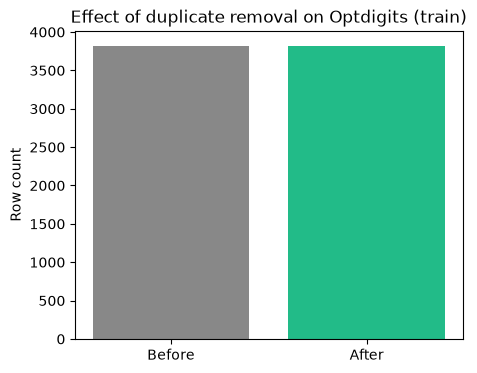

In [ ]:
# --- EDA visualization: rows before vs after duplicate removal ---
plt.figure(figsize=(5,4))
plt.bar(["Before", "After"], [n_before, n_after], color=["#888","#2b8"])
plt.ylabel("Row count")
plt.title("Effect of duplicate removal on Optdigits (train)")
plt.savefig("../../results/eda_visualizations/member1_duplicates_bar.png", dpi=150, bbox_inches="tight")
plt.show()

## Model Evaluation

A Decision Tree is a suitable interpretable multiclass baseline for the 64 pixel features. This experiment checks whether duplicate removal changes performance by tuning the same tree on the original and deduplicated training rows. `GridSearchCV` evaluates max depth, split size, and leaf size with 5-fold stratified CV; the held-out UCI test split is used only for final accuracy and macro F1. Macro F1 weights all ten digits equally.

,Training data,CV accuracy,CV macro F1,Test accuracy,Test precision (macro),Test recall (macro),Test macro F1,Best parameters
0,Before duplicate removal,0.897983,0.898244,0.856427,0.858284,0.8564,0.856188,"{'max_depth': None, 'min_samples_leaf': 1, 'mi..."
1,After duplicate removal,0.897983,0.898244,0.856427,0.858284,0.8564,0.856188,"{'max_depth': None, 'min_samples_leaf': 1, 'mi..."


CV-selected model: Before duplicate removal
Classification report on the held-out official test split:
              precision    recall  f1-score   support

           0     0.9293    0.9607    0.9448       178
           1     0.7843    0.8791    0.8290       182
           2     0.8333    0.8192    0.8262       177
           3     0.8817    0.8142    0.8466       183
           4     0.8204    0.7569    0.7874       181
           5     0.8824    0.9066    0.8943       182
           6     0.9659    0.9392    0.9524       181
           7     0.8861    0.7821    0.8309       179
           8     0.7617    0.8448    0.8011       174
           9     0.8378    0.8611    0.8493       180

    accuracy                         0.8564      1797
   macro avg     0.8583    0.8564    0.8562      1797
weighted avg     0.8586    0.8564    0.8563      1797



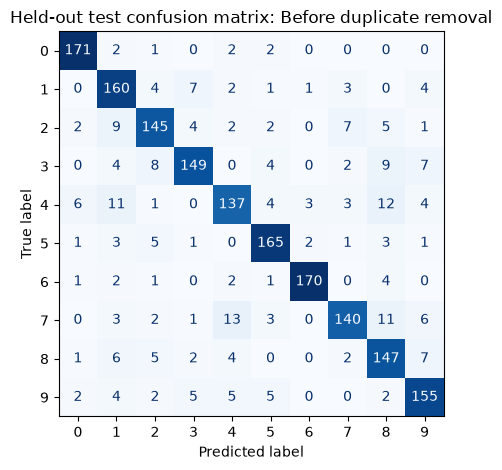

In [4]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

feature_cols = [f"pixel_{index}" for index in range(64)]
y_test = test["target"].astype(int)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
training_variants = {
    "Before duplicate removal": train,
    "After duplicate removal": train_clean,
}
results = []
best_models = {}
for variant_name, variant_data in training_variants.items():
    search = GridSearchCV(
        DecisionTreeClassifier(random_state=42),
        {
            "max_depth": [None, 20, 35],
            "min_samples_split": [2, 5],
            "min_samples_leaf": [1, 2],
        },
        scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
        refit="macro_f1",
        cv=cv,
        n_jobs=-1,
    )
    search.fit(variant_data[feature_cols], variant_data["target"].astype(int))
    best_models[variant_name] = search.best_estimator_
    predictions = search.predict(test[feature_cols])
    results.append({
        "Training data": variant_name,
        "CV accuracy": search.cv_results_["mean_test_accuracy"][search.best_index_],
        "CV macro F1": search.best_score_,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test precision (macro)": precision_score(y_test, predictions, average="macro"),
        "Test recall (macro)": recall_score(y_test, predictions, average="macro"),
        "Test macro F1": f1_score(y_test, predictions, average="macro"),
        "Best parameters": search.best_params_,
    })

cleaning_model_comparison = pd.DataFrame(results).sort_values(
    "CV macro F1", ascending=False
).reset_index(drop=True)
display(cleaning_model_comparison)

best_variant = cleaning_model_comparison.loc[0, "Training data"]
best_predictions = best_models[best_variant].predict(test[feature_cols])
print(f"CV-selected model: {best_variant}")
print("Classification report on the held-out official test split:")
print(classification_report(y_test, best_predictions, digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, best_predictions, cmap="Blues", colorbar=False)
plt.title(f"Held-out test confusion matrix: {best_variant}")
plt.tight_layout()
plt.show()

### Results and conclusion

The dataset contained zero duplicate training rows, so the before/after variants are identical. The tuned Decision Tree achieved 89.82% CV macro F1 and 85.64% test accuracy in both cases. This demonstrates that duplicate removal preserves model results when there are no duplicates to remove; it cannot improve the score here. The tree is easy to explain but performed below the SVC and Random Forest results elsewhere in the project, suggesting its decision boundaries may be too simple or unstable for some digit shapes. Future work could compare ensemble trees or tune pruning more broadly. The single official test split and small parameter grid limit the strength of generalization claims.